<a href="https://colab.research.google.com/github/kusold/xcel-tou-calculator/blob/main/xcel_tou_analysis_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Xcel Energy Time-of-Use vs Flat Rate Billing Analysis

This notebook analyzes electrical usage data to compare costs between:
- **Flat Rate Billing**: Fixed rate per kWh based on season
- **Time of Use Billing**: Variable rates based on time of day and season

## Billing Rate Structure

### Flat Rate
- **Summer** (June 1 - Sep 30): $0.10380/kWh
- **Winter** (Oct 1 - May 31): $0.08570/kWh

### Time of Use
- **On-Peak** (5pm-9pm, Mon-Fri): Summer $0.21277/kWh, Winter $0.18331/kWh
- **Off-Peak** (all other times): Summer $0.07884/kWh, Winter $0.06792/kWh

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import pytz
import warnings
warnings.filterwarnings('ignore')

# Set timezone - Data is in Denver time (Mountain Time)
DENVER_TZ = pytz.timezone('America/Denver')
print(f"Analysis timezone: {DENVER_TZ}")

# Set plot style
plt.style.use('default')
sns.set_palette('husl')

print("Libraries imported successfully!")

Analysis timezone: America/Denver
Libraries imported successfully!


# Upload your CSV from your local filesystem

In [2]:
# Load and examine the CSV data
import io
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))
  # Read the CSV file into a pandas DataFrame
  df = pd.read_csv(io.StringIO(uploaded[fn].decode('utf-8')))


Saving XCEL_E_HOURLY_10-01-2024_10-01-2025.csv to XCEL_E_HOURLY_10-01-2024_10-01-2025 (1).csv
User uploaded file "XCEL_E_HOURLY_10-01-2024_10-01-2025 (1).csv" with length 296089 bytes


In [3]:
# Load and examine the CSV data
#df = pd.read_csv('XCEL_E_HOURLY_10-01-2024_10-01-2025.csv')

# Convert datetime and set as index (handle timezone properly)
df['Date and Time'] = pd.to_datetime(df['Date and Time'], utc=True)
df.set_index('Date and Time', inplace=True)
# Convert to local timezone for analysis
df.index = df.index.tz_convert('US/Mountain')

print(f"Data range: {df.index.min()} to {df.index.max()}")
print(f"Total records: {len(df):,}")
print(f"Total energy usage: {df['Interval kWh'].sum():.2f} kWh")
print(f"Index type: {type(df.index)}")
print("\nFirst 5 records:")
df.head()

Data range: 2024-10-01 00:00:00-06:00 to 2025-10-01 23:00:00-06:00
Total records: 8,737
Total energy usage: 10607.84 kWh
Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>

First 5 records:


,Interval kWh,Generated
Date and Time,,
2024-10-01 00:00:00-06:00,0.906,0
2024-10-01 01:00:00-06:00,0.818,0
2024-10-01 02:00:00-06:00,0.842,0
2024-10-01 03:00:00-06:00,0.784,0
2024-10-01 04:00:00-06:00,0.963,0


In [4]:
# Define billing rates based on AGENT.md specifications
FLAT_RATES = {
    'summer': 0.10380,  # June 1 - Sep 30
    'winter': 0.08570   # Oct 1 - May 31
}

TOU_RATES = {
    'summer_on_peak': 0.21277,   # 5pm-9pm, Mon-Fri, June-Sep
    'summer_off_peak': 0.07884,  # All other times, June-Sep
    'winter_on_peak': 0.18331,   # 5pm-9pm, Mon-Fri, Oct-May
    'winter_off_peak': 0.06792   # All other times, Oct-May
}

print("Billing rates defined:")
print(f"Flat Rate - Summer: ${FLAT_RATES['summer']:.5f}/kWh")
print(f"Flat Rate - Winter: ${FLAT_RATES['winter']:.5f}/kWh")
print(f"TOU - Summer On-Peak: ${TOU_RATES['summer_on_peak']:.5f}/kWh")
print(f"TOU - Winter On-Peak: ${TOU_RATES['winter_on_peak']:.5f}/kWh")

Billing rates defined:
Flat Rate - Summer: $0.10380/kWh
Flat Rate - Winter: $0.08570/kWh
TOU - Summer On-Peak: $0.21277/kWh
TOU - Winter On-Peak: $0.18331/kWh


In [5]:
# Function to categorize time periods
def categorize_time_period(timestamp):
    """
    Categorize timestamp into billing period type.

    Args:
        timestamp: pandas datetime object

    Returns:
        str: One of 'summer_on_peak', 'summer_off_peak', 'winter_on_peak', 'winter_off_peak'
    """
    month = timestamp.month
    hour = timestamp.hour
    weekday = timestamp.weekday()  # 0=Monday, 6=Sunday

    # Determine season (Summer: June-September)
    is_summer = month in [6, 7, 8, 9]

    # Determine if on-peak (5pm-9pm, Monday-Friday)
    is_on_peak = (17 <= hour < 21) and (weekday < 5)

    if is_summer:
        return 'summer_on_peak' if is_on_peak else 'summer_off_peak'
    else:
        return 'winter_on_peak' if is_on_peak else 'winter_off_peak'

# Apply categorization to the dataset
df['period_type'] = df.index.map(categorize_time_period)
df['is_on_peak'] = df['period_type'].str.contains('on_peak')

print("Time period categorization applied!")
print("\nPeriod type distribution:")
print(df['period_type'].value_counts())

Time period categorization applied!

Period type distribution:
period_type
winter_off_peak    5128
summer_off_peak    2564
winter_on_peak      700
summer_on_peak      345
Name: count, dtype: int64


In [6]:
# Calculate usage percentages for on-peak vs off-peak
total_usage = df['Interval kWh'].sum()
on_peak_usage = df[df['is_on_peak']]['Interval kWh'].sum()
off_peak_usage = df[~df['is_on_peak']]['Interval kWh'].sum()

on_peak_pct = (on_peak_usage / total_usage) * 100
off_peak_pct = (off_peak_usage / total_usage) * 100

print("=" * 50)
print("ENERGY USAGE BREAKDOWN")
print("=" * 50)
print(f"Total Usage: {total_usage:,.2f} kWh")
print(f"On-Peak Usage: {on_peak_usage:,.2f} kWh ({on_peak_pct:.1f}%)")
print(f"Off-Peak Usage: {off_peak_usage:,.2f} kWh ({off_peak_pct:.1f}%)")

ENERGY USAGE BREAKDOWN
Total Usage: 10,607.84 kWh
On-Peak Usage: 1,612.68 kWh (15.2%)
Off-Peak Usage: 8,995.17 kWh (84.8%)


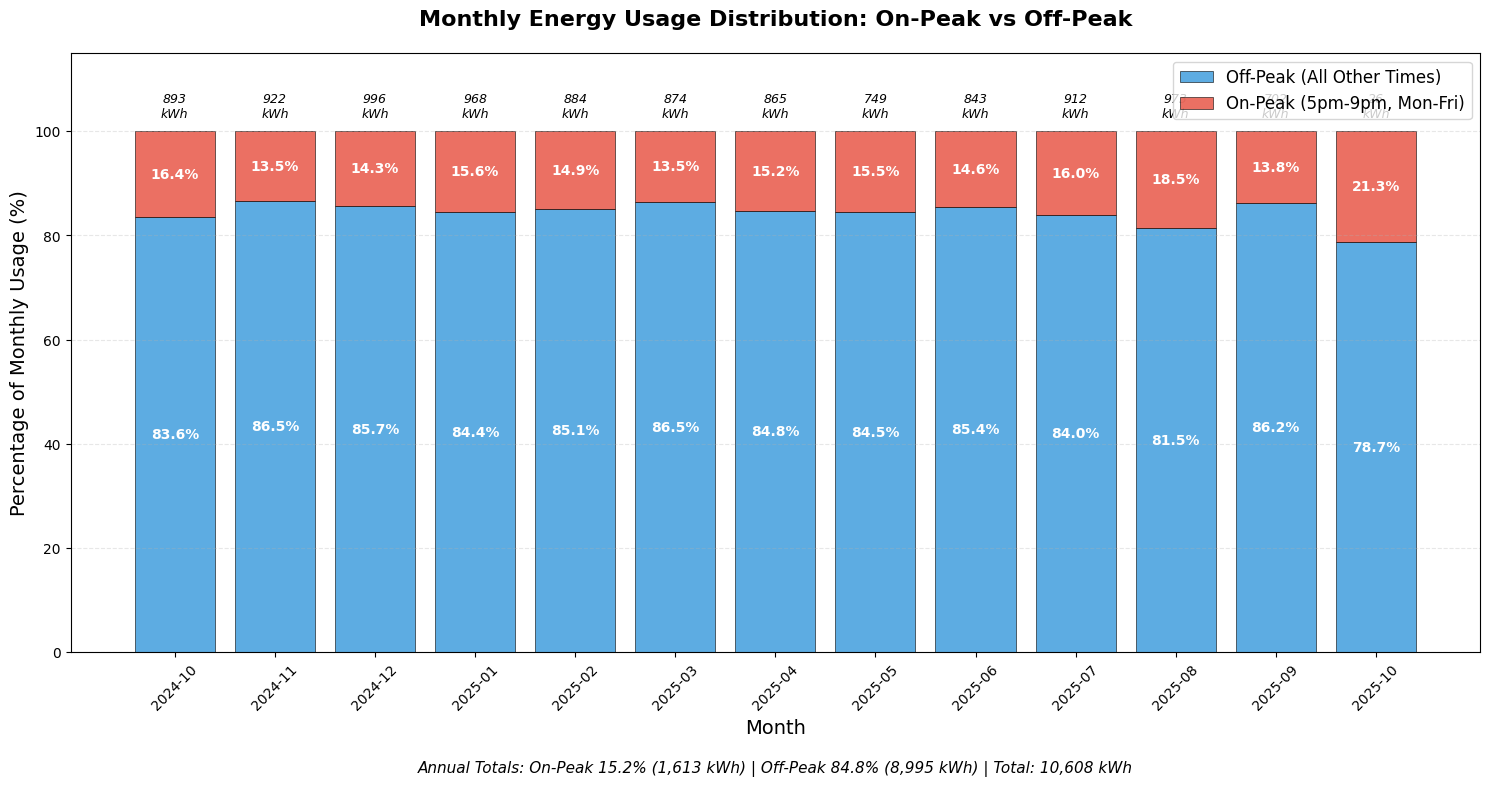

In [7]:
# Create stacked bar chart showing monthly on-peak vs off-peak usage distribution
# Calculate monthly on-peak and off-peak usage
# First create month column from datetime index
df['month'] = df.index.to_series().dt.strftime('%Y-%m')

monthly_peak_usage = df[df['is_on_peak']].groupby('month')['Interval kWh'].sum()
monthly_offpeak_usage = df[~df['is_on_peak']].groupby('month')['Interval kWh'].sum()
monthly_total_usage = df.groupby('month')['Interval kWh'].sum()

# Calculate percentages for each month
monthly_peak_pct = (monthly_peak_usage / monthly_total_usage) * 100
monthly_offpeak_pct = (monthly_offpeak_usage / monthly_total_usage) * 100

fig, ax = plt.subplots(figsize=(15, 8))

months = monthly_total_usage.index
x_pos = range(len(months))

# Create stacked bars - off-peak on bottom, on-peak on top
bars1 = ax.bar(x_pos, monthly_offpeak_pct, color='#3498db', alpha=0.8,
               label='Off-Peak (All Other Times)', edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x_pos, monthly_peak_pct, bottom=monthly_offpeak_pct,
               color='#e74c3c', alpha=0.8, label='On-Peak (5pm-9pm, Mon-Fri)',
               edgecolor='black', linewidth=0.5)

# Add percentage labels on each segment
for i, (month, peak_pct, offpeak_pct, total_kwh) in enumerate(zip(months, monthly_peak_pct, monthly_offpeak_pct, monthly_total_usage)):
    # Off-peak label (middle of bottom segment)
    if offpeak_pct > 5:  # Only show label if segment is large enough
        ax.text(i, offpeak_pct/2, f'{offpeak_pct:.1f}%',
                ha='center', va='center', fontsize=10, fontweight='bold', color='white')

    # On-peak label (middle of top segment)
    if peak_pct > 3:  # Only show label if segment is large enough
        ax.text(i, offpeak_pct + peak_pct/2, f'{peak_pct:.1f}%',
                ha='center', va='center', fontsize=10, fontweight='bold', color='white')

    # Total kWh usage label above bar
    ax.text(i, 102, f'{total_kwh:,.0f}\nkWh',
            ha='center', va='bottom', fontsize=9, style='italic')

ax.set_xlabel('Month', fontsize=14)
ax.set_ylabel('Percentage of Monthly Usage (%)', fontsize=14)
ax.set_title('Monthly Energy Usage Distribution: On-Peak vs Off-Peak', fontsize=16, fontweight='bold', pad=20)
ax.set_xticks(x_pos)
ax.set_xticklabels(months, rotation=45)
ax.set_ylim(0, 115)  # Extra space for kWh labels
ax.legend(loc='upper right', fontsize=12)
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Add overall statistics as subtitle
ax.text(0.5, -0.2, f'Annual Totals: On-Peak {on_peak_pct:.1f}% ({on_peak_usage:,.0f} kWh) | Off-Peak {off_peak_pct:.1f}% ({off_peak_usage:,.0f} kWh) | Total: {total_usage:,.0f} kWh',
        transform=ax.transAxes, ha='center', fontsize=11, style='italic')

plt.tight_layout()
plt.show()

In [8]:
# Calculate monthly costs for both billing methods
# Use month column already created in previous cell
monthly_usage = df.groupby(['month', 'period_type'])['Interval kWh'].sum().unstack(fill_value=0)

print("Monthly usage by period type:")
print(monthly_usage.round(2))

monthly_costs = pd.DataFrame(index=monthly_usage.index)

# Calculate flat rate costs
for month in monthly_usage.index:
    month_num = int(month.split('-')[1])  # Extract month from 'YYYY-MM' format
    is_summer = month_num in [6, 7, 8, 9]
    rate = FLAT_RATES['summer'] if is_summer else FLAT_RATES['winter']
    total_usage_month = monthly_usage.loc[month].sum()
    monthly_costs.loc[month, 'Flat Rate'] = total_usage_month * rate

# Calculate TOU costs
for month in monthly_usage.index:
    tou_cost = 0
    for period in monthly_usage.columns:
        if period in TOU_RATES:
            usage = monthly_usage.loc[month, period]
            rate = TOU_RATES[period]
            tou_cost += usage * rate
    monthly_costs.loc[month, 'Time of Use'] = tou_cost

# Calculate savings (positive = flat rate costs more)
monthly_costs['Savings with TOU'] = monthly_costs['Flat Rate'] - monthly_costs['Time of Use']

print("\nMonthly cost comparison:")
monthly_costs.round(2)

Monthly usage by period type:
period_type  summer_off_peak  summer_on_peak  winter_off_peak  winter_on_peak
month                                                                        
2024-10                 0.00            0.00           746.44          146.58
2024-11                 0.00            0.00           798.11          124.13
2024-12                 0.00            0.00           853.67          142.40
2025-01                 0.00            0.00           817.28          150.84
2025-02                 0.00            0.00           752.79          131.58
2025-03                 0.00            0.00           756.06          118.03
2025-04                 0.00            0.00           733.17          131.70
2025-05                 0.00            0.00           632.65          115.89
2025-06               720.37          122.94             0.00            0.00
2025-07               766.26          145.85             0.00            0.00
2025-08               792.92      

,Flat Rate,Time of Use,Savings with TOU
month,,,
2024-10,76.53,77.57,-1.04
2024-11,79.04,76.96,2.07
2024-12,85.36,84.08,1.28
2025-01,82.97,83.16,-0.19
2025-02,75.79,75.25,0.54
2025-03,74.91,72.99,1.92
2025-04,74.12,73.94,0.18
2025-05,64.15,64.21,-0.06
2025-06,87.54,82.95,4.58


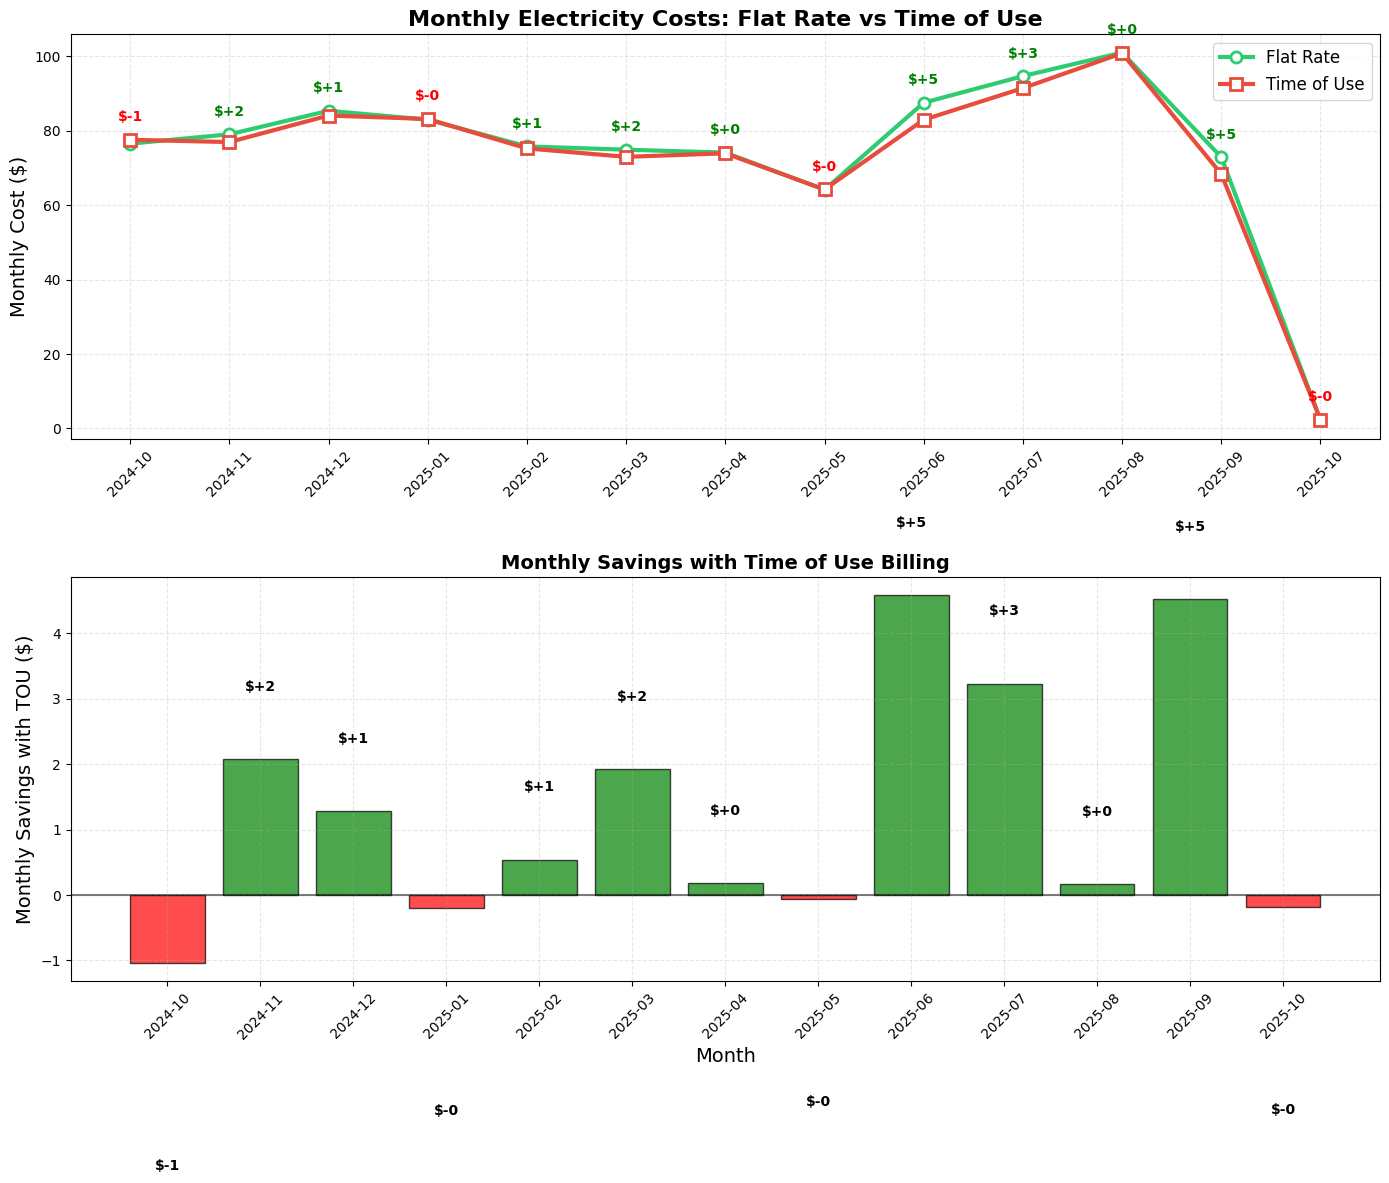

In [9]:
# Create line chart comparing monthly costs
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12))

months = [str(m) for m in monthly_costs.index]
x_pos = range(len(months))

# Main cost comparison chart
ax1.plot(x_pos, monthly_costs['Flat Rate'], marker='o', linewidth=3,
         label='Flat Rate', color='#2ecc71', markersize=8, markerfacecolor='white', markeredgewidth=2)
ax1.plot(x_pos, monthly_costs['Time of Use'], marker='s', linewidth=3,
         label='Time of Use', color='#e74c3c', markersize=8, markerfacecolor='white', markeredgewidth=2)

# Customize the main chart
ax1.set_ylabel('Monthly Cost ($)', fontsize=14)
ax1.set_title('Monthly Electricity Costs: Flat Rate vs Time of Use', fontsize=16, fontweight='bold')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(months, rotation=45)
ax1.legend(fontsize=12)
ax1.grid(True, alpha=0.3, linestyle='--')

# Add cost difference annotations
for i, savings in enumerate(monthly_costs['Savings with TOU']):
    flat_cost = monthly_costs['Flat Rate'].iloc[i]
    tou_cost = monthly_costs['Time of Use'].iloc[i]
    y_pos = max(flat_cost, tou_cost) + 5
    color = 'green' if savings > 0 else 'red'
    ax1.annotate(f'${savings:+.0f}', (i, y_pos),
                ha='center', fontsize=10, color=color, fontweight='bold')

# Savings chart
colors = ['green' if x > 0 else 'red' for x in monthly_costs['Savings with TOU']]
bars = ax2.bar(x_pos, monthly_costs['Savings with TOU'], color=colors, alpha=0.7, edgecolor='black')

# Add value labels on bars
for bar, value in zip(bars, monthly_costs['Savings with TOU']):
    height = bar.get_height()
    label_y = height + 1 if height >= 0 else height - 3
    ax2.text(bar.get_x() + bar.get_width()/2., label_y,
             f'${value:+.0f}', ha='center', va='bottom' if height >= 0 else 'top',
             fontsize=10, fontweight='bold')

ax2.set_xlabel('Month', fontsize=14)
ax2.set_ylabel('Monthly Savings with TOU ($)', fontsize=14)
ax2.set_title('Monthly Savings with Time of Use Billing', fontsize=14, fontweight='bold')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(months, rotation=45)
ax2.grid(True, alpha=0.3, linestyle='--')
ax2.axhline(y=0, color='black', linestyle='-', alpha=0.5)

plt.tight_layout()
plt.show()

In [10]:
# Summary statistics and final analysis
total_flat_cost = monthly_costs['Flat Rate'].sum()
total_tou_cost = monthly_costs['Time of Use'].sum()
total_savings = total_flat_cost - total_tou_cost
avg_monthly_usage = total_usage / len(monthly_costs)

print("=" * 60)
print("ANNUAL BILLING COMPARISON SUMMARY")
print("=" * 60)
print(f"Data Period: {df.index.min().strftime('%B %Y')} to {df.index.max().strftime('%B %Y')}")
print(f"Total Annual Usage: {total_usage:,.0f} kWh")
print(f"Average Monthly Usage: {avg_monthly_usage:,.0f} kWh")
print()
print("COST COMPARISON:")
print(f"Flat Rate Total Cost: ${total_flat_cost:,.2f}")
print(f"Time of Use Total Cost: ${total_tou_cost:,.2f}")
print()
print("SAVINGS ANALYSIS:")
if total_savings > 0:
    print(f"✅ Annual Savings with TOU: ${total_savings:,.2f}")
    print(f"💰 Percentage Savings: {(total_savings/total_flat_cost)*100:.1f}%")
    print(f"📊 Average Monthly Savings: ${total_savings/len(monthly_costs):.2f}")
else:
    print(f"❌ Annual Additional Cost with TOU: ${abs(total_savings):,.2f}")
    print(f"📈 Percentage Increase: {abs(total_savings/total_flat_cost)*100:.1f}%")
    print(f"📊 Average Monthly Additional Cost: ${abs(total_savings)/len(monthly_costs):.2f}")

print()
print("USAGE PATTERN INSIGHTS:")
print(f"On-Peak Usage: {on_peak_pct:.1f}% ({on_peak_usage:,.0f} kWh)")
print(f"Off-Peak Usage: {off_peak_pct:.1f}% ({off_peak_usage:,.0f} kWh)")

# Recommendation
print()
print("RECOMMENDATION:")
if total_savings > 50:  # Significant savings threshold
    print(f"🎯 STRONG RECOMMENDATION: Switch to Time of Use billing")
    print(f"   You could save ${total_savings:,.0f} annually ({(total_savings/total_flat_cost)*100:.1f}%)")
elif total_savings > 0:
    print(f"✅ RECOMMENDATION: Consider Time of Use billing")
    print(f"   Modest savings of ${total_savings:,.0f} annually ({(total_savings/total_flat_cost)*100:.1f}%)")
elif abs(total_savings) < 50:
    print(f"⚖️  NEUTRAL: Costs are similar between billing methods")
    print(f"   Difference: ${abs(total_savings):,.0f} annually")
else:
    print(f"❌ RECOMMENDATION: Stay with Flat Rate billing")
    print(f"   Time of Use would cost ${abs(total_savings):,.0f} more annually")

print("=" * 60)

ANNUAL BILLING COMPARISON SUMMARY
Data Period: October 2024 to October 2025
Total Annual Usage: 10,608 kWh
Average Monthly Usage: 816 kWh

COST COMPARISON:
Flat Rate Total Cost: $971.19
Time of Use Total Cost: $954.16

SAVINGS ANALYSIS:
✅ Annual Savings with TOU: $17.03
💰 Percentage Savings: 1.8%
📊 Average Monthly Savings: $1.31

USAGE PATTERN INSIGHTS:
On-Peak Usage: 15.2% (1,613 kWh)
Off-Peak Usage: 84.8% (8,995 kWh)

RECOMMENDATION:
✅ RECOMMENDATION: Consider Time of Use billing
   Modest savings of $17 annually (1.8%)
